# 05 — EfficientNet-B0 transfer learning (selected for Part 3)

Backbone: torchvision EfficientNet-B0, **IMAGENET1K_V1**.
Head: `Linear(1280, 3)`. Protocol: freeze backbone → train classifier → unfreeze `features.7` at `lr=1e-4`.
Input remains Part 1 224×224 ImageNet-normalised RGB; no separate preprocess path.

**Selection:** highest validation macro-F1 among the four trained models.


In [1]:
from pathlib import Path
import json
from IPython.display import Image, display, Markdown

from ml.engine.experiment_log import load_experiment_record
from ml.models import EfficientNetB0Classifier

ROOT = Path.cwd() if (Path.cwd() / "reports").exists() else Path.cwd().parent
rec = load_experiment_record(ROOT / "reports" / "experiments", "efficientnet_b0")
print("experiment_id:", rec["experiment_id"])
print("pretrained:", EfficientNetB0Classifier.pretrained_weights)
print("finetuned:", rec["finetuned"])
print("batch_size:", rec["batch_size"], "head lr:", rec["learning_rate"], "ft lr:", rec["epochs_configured"].get("finetune_lr"))
print("seconds:", round(rec["training_seconds"], 1))
print("best checkpoint:", rec["best_checkpoint"])


experiment_id: efficientnet_b0_20260918T043217Z
pretrained: IMAGENET1K_V1
finetuned: True
batch_size: 16 head lr: 0.001 ft lr: 0.0001
seconds: 1037.8
best checkpoint: C:\Users\Karthick\Intelligent Disaster Damage Assessment using Deep Learning\models\efficientnet_b0\best.pt


VAL  acc=0.7660  macro-F1=0.6536  mild F1=0.3541 rec=0.3983
TEST acc=0.7828  macro-F1=0.6418  (reported after selection; not used to pick the model)
{
  "little_or_none": {
    "precision": 0.8910034602076125,
    "recall": 0.8571428571428571,
    "f1": 0.8737452283330976,
    "support": 3605
  },
  "mild": {
    "precision": 0.3187066974595843,
    "recall": 0.39826839826839827,
    "f1": 0.354073123797306,
    "support": 693
  },
  "severe": {
    "precision": 0.7402452619843924,
    "recall": 0.7256830601092896,
    "f1": 0.7328918322295805,
    "support": 1830
  }
}


# Part 2 model comparison (actual runs)

Source files (do not edit by hand):

- `baseline_20260917T192440Z.json`
- `custom_cnn_20260917T194811Z.json`
- `resnet50_20260918T041051Z.json`
- `efficientnet_b0_20260918T043217Z.json`

Shared protocol: MEDIC v1.0 official split, Part 1 224×224 ImageNet preprocess,
train-only augmentation, `CrossEntropyLoss` with `data/metadata/class_weights.json`,
AdamW, seed 42, CUDA + AMP. Model selection uses **validation macro-F1**.
Test numbers were computed **once after** checkpoint selection.

## Validation (n = 6,128)

| Model | Status | Epochs run | Batch | LR (head / FT) | Time | Acc | Macro-F1 | Mild F1 | Mild recall |
|---|---|---:|---:|---|---:|---:|---:|---:|---:|
| LinearBaseline | trained + evaluated | 6 | 128 | 1e-3 / — | 22.6 min | 0.4953 | 0.4374 | 0.2111 | 0.3766 |
| CustomCNN | trained + evaluated | 7 (early stop) | 32 | 1e-3 / — | 501.4 min | 0.5852 | 0.5097 | 0.2361 | 0.4156 |
| ResNet-50 | trained + evaluated | 5 head + 4 FT | 16 | 1e-3 / 1e-4 | 20.1 min | 0.7805 | 0.6463 | 0.3172 | 0.3030 |
| EfficientNet-B0 | trained + evaluated | 5 head + 4 FT | 16 | 1e-3 / 1e-4 | 17.3 min | 0.7660 | **0.6536** | **0.3541** | **0.3983** |

Validation F1 by class:

| Model | little_or_none | mild | severe |
|---|---:|---:|---:|
| LinearBaseline | 0.625 | 0.211 | 0.476 |
| CustomCNN | 0.731 | 0.236 | 0.562 |
| ResNet-50 | 0.885 | 0.317 | 0.736 |
| EfficientNet-B0 | 0.874 | 0.354 | 0.733 |

## Isolated test (n = 15,630) — not used for selection

| Model | Acc | Macro-F1 | Mild F1 |
|---|---:|---:|---:|
| LinearBaseline | 0.5358 | 0.4391 | 0.1852 |
| CustomCNN | 0.6294 | 0.5185 | 0.2286 |
| ResNet-50 | 0.8070 | 0.6447 | 0.2982 |
| EfficientNet-B0 | 0.7828 | 0.6418 | 0.3256 |

## Selection for Part 3

**EfficientNet-B0** (`models/efficientnet_b0/best.pt`).

Reason: highest **validation macro-F1** (0.6536 vs ResNet-50 0.6463) and the
strongest **mild** F1/recall on the validation set. ResNet-50 has higher
overall accuracy (val 0.7805 / test 0.8070) but weaker minority-class recall.

Mild remains the hard class on every model. Part 3 should analyse that gap.


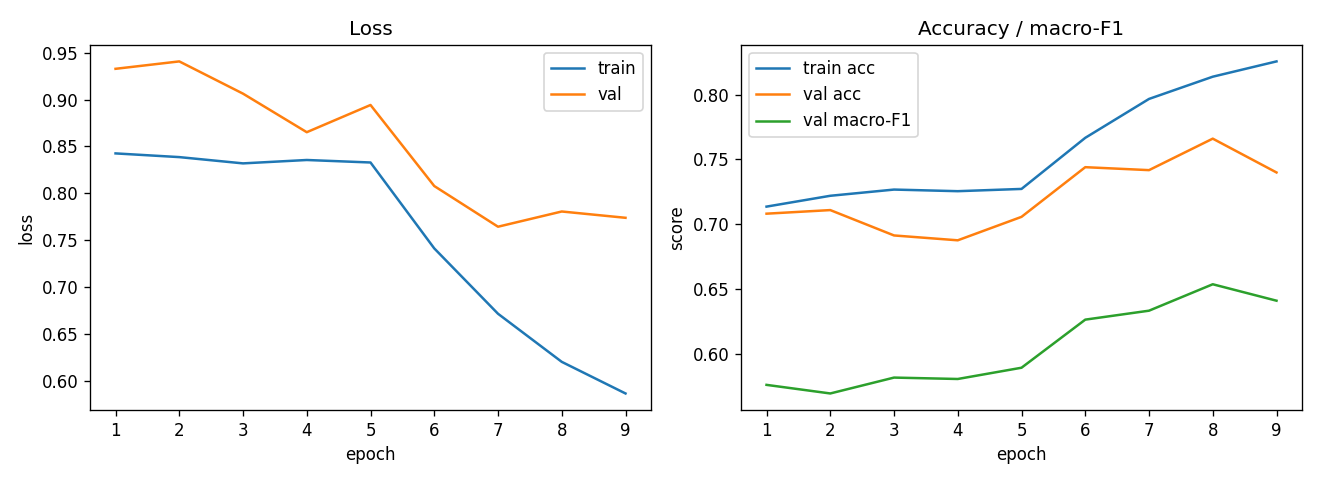

In [2]:
vm, tm = rec["val_metrics"], rec["test_metrics"]
print("VAL  acc={:.4f}  macro-F1={:.4f}  mild F1={:.4f} rec={:.4f}".format(
    vm["accuracy"], vm["macro_f1"], vm["per_class"]["mild"]["f1"], vm["per_class"]["mild"]["recall"]))
print("TEST acc={:.4f}  macro-F1={:.4f}  (reported after selection; not used to pick the model)".format(
    tm["accuracy"], tm["macro_f1"]))
print(json.dumps(vm["per_class"], indent=2))
cmp = ROOT / "reports" / "experiments" / "comparison.md"
display(Markdown(cmp.read_text(encoding="utf-8")))
curve = Path(rec["curves"])
display(Image(filename=str(curve))) if curve.exists() else print("missing", curve)
